# USA 98 Airfoil — 2D Navier–Stokes Flow Simulation (Lattice Boltzmann), batch edition

This notebook processes a **whole folder** of XFOIL-style airfoil JSON files (the same format used before —
`xps/yps` = pressure side, `xss/yss` = suction side, plus an optional `polars` list) instead of a single file.

For every JSON file in `JSON_FOLDER`, it:
1. Loads the airfoil geometry and plots its shape.
2. Simulates 2D incompressible viscous flow around it with a D2Q9 Lattice-Boltzmann solver.
3. Saves a vorticity result (a static final-frame image, or a full `.mp4` animation if you turn that on).
4. Compares the simulated Reynolds number / AoA against the airfoil's bundled XFOIL `Cl`/`Cd` polar, if present.
5. Writes everything into its own subfolder under `RESULTS_DIR`, and rolls all the airfoils up into one
   `batch_summary.csv`.

A single malformed/incomplete JSON won't stop the batch — it's caught, logged to `batch_failures.csv`, and
the run continues with the next file. Run the **sanity-check cell** on one airfoil first (Section 7) before
kicking off the full folder — it also gives you a time estimate for the whole batch.

In [14]:
import json
import os
import glob
import csv
import time
import traceback
import gc

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from matplotlib.path import Path
from IPython.display import HTML, display

plt.rcParams['figure.dpi'] = 100

## 1. Configure the input folder and the results folder

In [15]:
JSON_PATH = "data\\raw\\json\\ys930-il - YS-930.json"   
JSON_FOLDER = "data\\raw\\json"                          
RESULTS_DIR = "data\\raw\\sim_graphs"                      

json_files = sorted(glob.glob(os.path.join(JSON_FOLDER, "*.json")))
print(f"Found {len(json_files)} JSON file(s) in '{JSON_FOLDER}'")
os.makedirs(RESULTS_DIR, exist_ok=True)

Found 825 JSON file(s) in 'data\raw\json'


## 2. Simulation parameters (used for every airfoil in the batch)

- **AoA**: angle of attack in degrees (rotates the airfoil relative to the horizontal incoming flow)
- **U0**: inlet/free-stream speed, in lattice units (keep well below ~0.15 for numerical stability)
- **TAU**: LBM relaxation time -> controls viscosity / Reynolds number
- **SAVE_ANIMATION**: `False` (default) saves one static final-frame PNG per airfoil, which is fast and has
  no external dependency. Set to `True` to save a full `.mp4` per airfoil instead — this needs `ffmpeg` on
  your system and is much slower over a big folder.
- **SAVE_DEBUG_PLOTS**: also save the obstacle-mask PNG for every airfoil (useful while tuning `CHORD_PX`/`X0`/`Y0`).

In [16]:

AoA = 5.0           # angle of attack, degrees
U0 = 0.08            # inlet speed (lattice units)
TAU = 0.6            # relaxation time -> viscosity
NX, NY = 360, 120    # grid size
CHORD_PX = 90        # airfoil chord in grid cells
X0, Y0 = 70, NY // 2  # airfoil placement (quarter-chord pivot) in the grid
N_STEPS = 1600
SAMPLE_EVERY = 8


SAVE_ANIMATION = False     # True -> save airfoil_flow.mp4 per airfoil (slow, needs ffmpeg)
SAVE_DEBUG_PLOTS = False   # True -> also save obstacle_mask.png per airfoil

nu = (TAU - 0.5) / 3.0
Re = U0 * CHORD_PX / nu
print(f"AoA = {AoA} deg | U0 = {U0} | TAU = {TAU} -> nu = {nu:.5f} | Re (chord-based) ~= {Re:.0f}")

AoA = 5.0 deg | U0 = 0.08 | TAU = 0.6 -> nu = 0.03333 | Re (chord-based) ~= 216


## 3. D2Q9 lattice constants (shared by every airfoil — built once)

In [17]:

NL = 9
cxs = np.array([0, 0, 1, 1, 1, 0, -1, -1, -1])
cys = np.array([0, 1, 1, 0, -1, -1, -1, 0, 1])
weights = np.array([4/9, 1/9, 1/36, 1/9, 1/36, 1/9, 1/36, 1/9, 1/36])
opposite = np.array([0, 5, 6, 7, 8, 1, 2, 3, 4])  

def equilibrium(rho, ux, uy):
    feq = np.zeros((*rho.shape, NL))
    for i, cx, cy, w in zip(range(NL), cxs, cys, weights):
        cu = cx * ux + cy * uy
        feq[..., i] = rho * w * (1 + 3*cu + 4.5*cu**2 - 1.5*(ux**2 + uy**2))
    return feq

## 4. Reusable building blocks: load geometry, build obstacle mask, run the LBM solver

In [18]:
def load_airfoil_geometry(json_path):
    '''Load one XFOIL-style JSON and build its closed airfoil polygon (chord = 1.0, LE at x=0, TE at x=1).'''
    with open(json_path) as f:
        airfoil_data = json.load(f)

    xps, yps = np.array(airfoil_data['xps']), np.array(airfoil_data['yps'])  # pressure side (LE->TE)
    xss, yss = np.array(airfoil_data['xss']), np.array(airfoil_data['yss'])  # suction side (LE->TE)

    # TE -> LE along the suction side (reversed), then LE -> TE along the pressure side
    poly_x = np.concatenate([xss[::-1], xps[1:]])
    poly_y = np.concatenate([yss[::-1], yps[1:]])
    polygon = np.column_stack([poly_x, poly_y])
    return airfoil_data, xps, yps, xss, yss, polygon

In [19]:
def build_obstacle_mask(nx, ny, polygon, chord_px, x0, y0, aoa_deg, pivot=0.25):
    '''Rotate/scale/place the normalized airfoil polygon onto the (ny, nx) flow grid
    and rasterize it into a boolean solid/fluid mask (point-in-polygon test).'''
    theta = -np.radians(aoa_deg)  # pitch the airfoil up by AoA relative to horizontal flow
    px = polygon[:, 0] - pivot
    py = polygon[:, 1]
    rx = px * np.cos(theta) - py * np.sin(theta) + pivot
    ry = px * np.sin(theta) + py * np.cos(theta)
    gx = x0 + rx * chord_px
    gy = y0 + ry * chord_px
    path = Path(np.column_stack([gx, gy]))

    Y, X = np.mgrid[0:ny, 0:nx]
    pts = np.column_stack([X.ravel(), Y.ravel()])
    mask = path.contains_points(pts).reshape(ny, nx)
    return mask, (gx, gy)

In [20]:
def run_lbm_simulation(obstacle, nx, ny, u0, tau, n_steps, sample_every, seed=0, verbose=False):
    '''2D D2Q9 BGK Lattice-Boltzmann solve around `obstacle`. Returns vorticity snapshots + final fields.'''
    rho = np.ones((ny, nx))
    ux = np.full((ny, nx), u0)
    uy = np.zeros((ny, nx))
    F = equilibrium(rho, ux, uy)

    # small perturbation to break symmetry and seed vortex shedding (fixed seed -> reproducible across airfoils)
    rng = np.random.default_rng(seed)
    F += 0.01 * u0 * rng.standard_normal((ny, nx, NL))

    frames = []
    for step in range(n_steps):
        # --- Streaming: each population moves one cell along its lattice direction ---
        for i in range(NL):
            F[:, :, i] = np.roll(F[:, :, i], cxs[i], axis=1)
            F[:, :, i] = np.roll(F[:, :, i], cys[i], axis=0)

        # --- Bounce-back: enforce no-slip on the airfoil surface ---
        bounced = F[obstacle, :][:, opposite]

        # --- Macroscopic quantities ---
        rho = np.sum(F, axis=2)
        ux = np.sum(F * cxs, axis=2) / rho
        uy = np.sum(F * cys, axis=2) / rho

        F[obstacle, :] = bounced
        ux[obstacle] = 0.0
        uy[obstacle] = 0.0

        # --- Collision (BGK relaxation toward equilibrium) ---
        Feq = equilibrium(rho, ux, uy)
        F += -(1.0 / tau) * (F - Feq)

        if step % sample_every == 0:
            duy_dx = np.gradient(uy, axis=1)
            dux_dy = np.gradient(ux, axis=0)
            vorticity = duy_dx - dux_dy
            vorticity[obstacle] = np.nan
            frames.append(vorticity.copy())

        if verbose and step % 400 == 0:
            print(f"    step {step}/{n_steps}")

    return frames, ux, uy, rho

## 5. Reusable plotting/saving helpers (each one saves to disk and closes its figure)

In [21]:
def save_airfoil_shape_plot(airfoil_data, xps, yps, xss, yss, poly_x, poly_y, out_path, show=False):
    fig, ax = plt.subplots(figsize=(9, 3))
    ax.plot(xss, yss, color='#1f77b4', lw=2, label='Suction side (upper)')
    ax.plot(xps, yps, color='#d62728', lw=2, label='Pressure side (lower)')
    ax.fill(poly_x, poly_y, color='#8ecae6', alpha=0.4)
    ax.axhline(0, color='gray', lw=0.5, ls='--')
    ax.set_aspect('equal')
    ax.set_xlabel('x / chord'); ax.set_ylabel('y / chord')
    ax.set_title(f"{airfoil_data.get('name', 'airfoil')} geometry")
    ax.legend(loc='upper right')
    plt.tight_layout()
    fig.savefig(out_path, dpi=150)
    if show:
        plt.show()
    plt.close(fig)


def save_obstacle_mask_plot(obstacle, aoa, out_path, show=False):
    fig = plt.figure(figsize=(8, 3))
    plt.imshow(obstacle, origin='lower', cmap='gray_r')
    plt.title(f'Obstacle mask (AoA = {aoa} deg)')
    plt.xlabel('x (grid)'); plt.ylabel('y (grid)')
    plt.tight_layout()
    fig.savefig(out_path, dpi=150)
    if show:
        plt.show()
    plt.close(fig)

In [22]:
def save_vorticity_final_plot(frames, airfoil_gx, airfoil_gy, name, aoa, re, out_path, show=False):
    '''Fast default: save just the final vorticity snapshot as a PNG.'''
    vmax = np.nanpercentile(np.abs(np.array(frames)), 99)
    fig, ax = plt.subplots(figsize=(10, 3.6))
    cmap = plt.get_cmap('RdBu_r').copy()
    cmap.set_bad('#444444')
    ax.imshow(frames[-1], origin='lower', cmap=cmap, vmin=-vmax, vmax=vmax)
    ax.plot(airfoil_gx, airfoil_gy, color='black', lw=1.2)
    ax.set_title(f"Vorticity around {name} (final frame)  |  AoA={aoa} deg, Re~={re:.0f}")
    ax.set_xlabel('x (grid cells)'); ax.set_ylabel('y (grid cells)')
    plt.tight_layout()
    fig.savefig(out_path, dpi=150)
    if show:
        plt.show()
    plt.close(fig)


def save_vorticity_animation(frames, airfoil_gx, airfoil_gy, name, aoa, re, out_path, show=False):
    '''Full animation, saved as .mp4 (requires ffmpeg). Falls back to a static PNG if ffmpeg is missing.'''
    vmax = np.nanpercentile(np.abs(np.array(frames)), 99)
    fig, ax = plt.subplots(figsize=(10, 3.6))
    cmap = plt.get_cmap('RdBu_r').copy()
    cmap.set_bad('#444444')
    im = ax.imshow(frames[0], origin='lower', cmap=cmap, vmin=-vmax, vmax=vmax, animated=True)
    ax.plot(airfoil_gx, airfoil_gy, color='black', lw=1.2)
    ax.set_title(f"Vorticity around {name}  |  AoA={aoa} deg, Re~={re:.0f}")
    ax.set_xlabel('x (grid cells)'); ax.set_ylabel('y (grid cells)')
    cbar = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02)
    cbar.set_label('vorticity')
    plt.tight_layout()

    def update(i):
        im.set_array(frames[i])
        return (im,)

    anim = animation.FuncAnimation(fig, update, frames=len(frames), interval=40, blit=True)

    try:
        anim.save(out_path, writer='ffmpeg', fps=25, dpi=130)
    except Exception as e:
        print(f"    Could not save animation ({e}); saving a static final-frame image instead.")
        static_path = os.path.splitext(out_path)[0] + '.png'
        im.set_array(frames[-1])
        fig.savefig(static_path, dpi=150)

    if show:
        display(HTML(anim.to_jshtml()))

    plt.close(fig)

In [23]:
def save_polar_comparison(airfoil_data, re_sim, aoa_sim, out_path, show=False):
    '''Plot this airfoil's bundled XFOIL Cl/Cd polar (closest Re, fixed Ncrit) next to the simulated AoA,
    and return the interpolated XFOIL Cl/Cd at that AoA for the summary table.'''
    polars = airfoil_data['polars']
    alphas = np.array([p['alpha'] for p in polars])
    Cls = np.array([p['Cl'] for p in polars])
    Cds = np.array([p['Cd'] for p in polars])
    Res = np.array([p['Re'] for p in polars])
    Ncrits = np.array([p['Ncrit'] for p in polars])

    # Fix both Re AND Ncrit, since the JSON bundles multiple XFOIL runs per Re at different
    # Ncrit transition-sensitivity values -- otherwise points from different runs get connected out of order.
    closest_re = Res[np.argmin(np.abs(Res - re_sim))]
    ncrit_choice = 9.0 if (Ncrits == 9.0).any() else np.unique(Ncrits)[0]
    sel = (Res == closest_re) & (Ncrits == ncrit_choice)
    order = np.argsort(alphas[sel])
    a_sel, cl_sel, cd_sel = alphas[sel][order], Cls[sel][order], Cds[sel][order]

    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(a_sel, cl_sel, marker='o', ms=3)
    axes[0].axvline(aoa_sim, color='red', ls='--', label=f'Simulated AoA = {aoa_sim} deg')
    axes[0].set_xlabel('Angle of attack (deg)'); axes[0].set_ylabel('Cl')
    axes[0].set_title(f'Lift coefficient (XFOIL, Re={closest_re:.0f}, Ncrit={ncrit_choice:.0f})')
    axes[0].legend(); axes[0].grid(alpha=0.3)

    axes[1].plot(a_sel, cd_sel, marker='o', ms=3, color='darkorange')
    axes[1].axvline(aoa_sim, color='red', ls='--', label=f'Simulated AoA = {aoa_sim} deg')
    axes[1].set_xlabel('Angle of attack (deg)'); axes[1].set_ylabel('Cd')
    axes[1].set_title(f'Drag coefficient (XFOIL, Re={closest_re:.0f}, Ncrit={ncrit_choice:.0f})')
    axes[1].legend(); axes[1].grid(alpha=0.3)

    plt.tight_layout()
    fig.savefig(out_path, dpi=150)
    if show:
        plt.show()
    plt.close(fig)

    cl_at_aoa = float(np.interp(aoa_sim, a_sel, cl_sel)) if len(a_sel) > 1 else None
    cd_at_aoa = float(np.interp(aoa_sim, a_sel, cd_sel)) if len(a_sel) > 1 else None

    return {
        'xfoil_closest_Re': float(closest_re),
        'xfoil_Ncrit': float(ncrit_choice),
        'xfoil_Cl_at_AoA': cl_at_aoa,
        'xfoil_Cd_at_AoA': cd_at_aoa,
    }

## 6. Full per-airfoil pipeline

This is exactly the single-file workflow from before (load -> plot shape -> build obstacle mask ->
run LBM -> plot/animate vorticity -> compare to XFOIL polar), wrapped as one function so it can run for
a single file (Section 7) or in a loop over the whole folder (Section 8). Every output goes into its own
`RESULTS_DIR/<airfoil name>/` subfolder, and the function returns a small summary dict for the batch table.

In [24]:
def process_one_airfoil(json_path, results_dir, aoa, u0, tau, nx, ny, chord_px, x0, y0,
                         n_steps, sample_every, save_animation=False, save_debug_plots=False, show=False):
    airfoil_data, xps, yps, xss, yss, polygon = load_airfoil_geometry(json_path)

    name = airfoil_data.get('name', os.path.splitext(os.path.basename(json_path))[0])
    safe_name = "".join(c if c.isalnum() or c in "-_ " else "_" for c in name).strip()
    out_dir = os.path.join(results_dir, safe_name)
    os.makedirs(out_dir, exist_ok=True)

    poly_x, poly_y = polygon[:, 0], polygon[:, 1]
    save_airfoil_shape_plot(airfoil_data, xps, yps, xss, yss, poly_x, poly_y,
                             os.path.join(out_dir, 'airfoil_shape.png'), show=show)

    obstacle, (airfoil_gx, airfoil_gy) = build_obstacle_mask(nx, ny, polygon, chord_px, x0, y0, aoa)
    if save_debug_plots:
        save_obstacle_mask_plot(obstacle, aoa, os.path.join(out_dir, 'obstacle_mask.png'), show=show)

    nu = (tau - 0.5) / 3.0
    re = u0 * chord_px / nu

    frames, ux, uy, rho = run_lbm_simulation(obstacle, nx, ny, u0, tau, n_steps, sample_every)

    if save_animation:
        save_vorticity_animation(frames, airfoil_gx, airfoil_gy, name, aoa, re,
                                  os.path.join(out_dir, 'airfoil_flow.mp4'), show=show)
    else:
        save_vorticity_final_plot(frames, airfoil_gx, airfoil_gy, name, aoa, re,
                                   os.path.join(out_dir, 'vorticity_final.png'), show=show)

    polar_info = {}
    if airfoil_data.get('polars'):
        polar_info = save_polar_comparison(airfoil_data, re, aoa,
                                            os.path.join(out_dir, 'xfoil_polar_reference.png'), show=show)

    summary = {
        'file': os.path.basename(json_path),
        'name': name,
        'AoA_deg': aoa,
        'Re_lbm': round(re, 1),
        'max_abs_vorticity_final': float(np.nanmax(np.abs(frames[-1]))) if frames else None,
        'solid_cells': int(obstacle.sum()),
    }
    summary.update(polar_info)
    return summary

## 7. Sanity-check on a single airfoil before running the full batch

Runs the full pipeline on just the first JSON in the folder, shows the plots inline (`show=True`), and
times it so you can estimate how long the whole folder will take with your current `N_STEPS`/grid size
before committing to it. If this particular file happens to be malformed, that's fine — the batch loop
below handles that per file and keeps going.

Running sanity check on: 2032c-il - 20-32C AIRFOIL.json


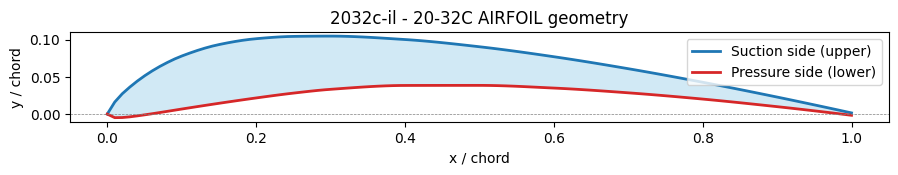

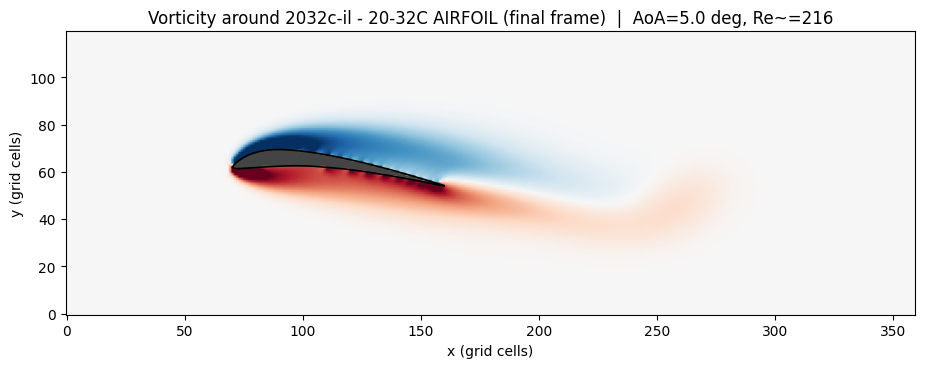

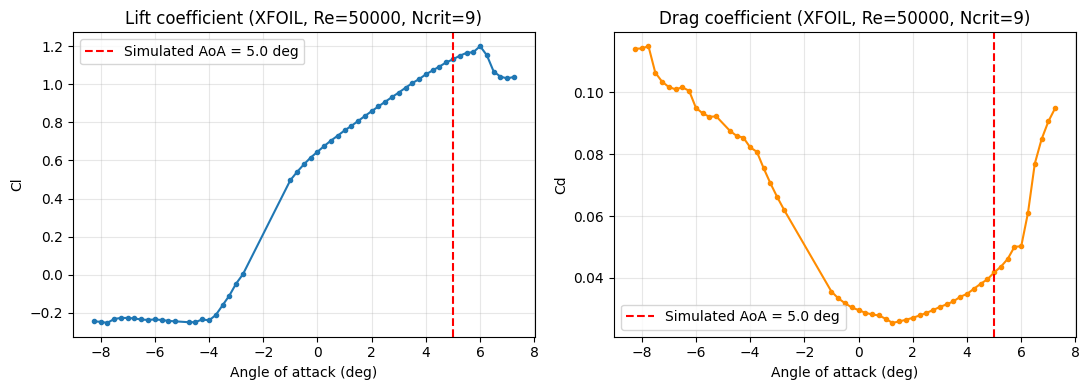


Sanity check summary: {'file': '2032c-il - 20-32C AIRFOIL.json', 'name': '2032c-il - 20-32C AIRFOIL', 'AoA_deg': 5.0, 'Re_lbm': 216.0, 'max_abs_vorticity_final': 0.03460179991709349, 'solid_cells': 376, 'xfoil_closest_Re': 50000.0, 'xfoil_Ncrit': 9.0, 'xfoil_Cl_at_AoA': 1.1311, 'xfoil_Cd_at_AoA': 0.04178}

This airfoil took 15.7s -> estimated total for 825 airfoils: 215.7 min


In [25]:
if json_files:
    test_path = json_files[0]
    print(f"Running sanity check on: {os.path.basename(test_path)}")
    t0 = time.time()
    try:
        test_summary = process_one_airfoil(
            test_path, RESULTS_DIR,
            aoa=AoA, u0=U0, tau=TAU, nx=NX, ny=NY,
            chord_px=CHORD_PX, x0=X0, y0=Y0,
            n_steps=N_STEPS, sample_every=SAMPLE_EVERY,
            save_animation=SAVE_ANIMATION, save_debug_plots=SAVE_DEBUG_PLOTS, show=True,
        )
        elapsed = time.time() - t0
        print("\nSanity check summary:", test_summary)
        print(f"\nThis airfoil took {elapsed:.1f}s -> estimated total for {len(json_files)} "
              f"airfoils: {elapsed * len(json_files) / 60:.1f} min")
    except Exception as e:
        print(f"Sanity check on {os.path.basename(test_path)} failed: {e}")
        print("(That's fine -- the batch loop below handles per-file errors and will just skip/log it.)")
    finally:
        plt.close('all')
else:
    print(f"No JSON files found in '{JSON_FOLDER}' -- check JSON_FOLDER above.")

## 8. Batch: run every airfoil in the folder

Loops over every `.json` in `JSON_FOLDER`. Each airfoil gets its own `RESULTS_DIR/<name>/` subfolder.
A failure on any one file is caught, logged, and skipped — it will not stop the rest of the batch.
Figures are closed and garbage-collected after each airfoil to keep memory flat across a large folder.

In [27]:
summaries = []
failed = []

for idx, json_path in enumerate(json_files, 1):
    fname = os.path.basename(json_path)
    print(f"[{idx}/{len(json_files)}] Processing {fname} ...")
    try:
        summary = process_one_airfoil(
            json_path, RESULTS_DIR,
            aoa=AoA, u0=U0, tau=TAU, nx=NX, ny=NY,
            chord_px=CHORD_PX, x0=X0, y0=Y0,
            n_steps=N_STEPS, sample_every=SAMPLE_EVERY,
            save_animation=SAVE_ANIMATION, save_debug_plots=SAVE_DEBUG_PLOTS, show=False,
        )
        summaries.append(summary)
    except Exception as e:
        print(f"    FAILED: {e}")
        failed.append({'file': fname, 'error': str(e)})
        traceback.print_exc()c
    finally:
        plt.close('all')
        gc.collect()

print(f"\nDone. {len(summaries)} succeeded, {len(failed)} failed.")

[1/825] Processing 2032c-il - 20-32C AIRFOIL.json ...


KeyboardInterrupt: 

## 9. Save and inspect the batch summary

In [28]:
summary_path = os.path.join(RESULTS_DIR, 'batch_summary.csv')
if summaries:
    fieldnames = list(summaries[0].keys())
    for s in summaries[1:]:
        for k in s.keys():
            if k not in fieldnames:
                fieldnames.append(k)
    with open(summary_path, 'w', newline='') as f:
        writer = csv.DictWriter(f, fieldnames=fieldnames)
        writer.writeheader()
        writer.writerows(summaries)
    print(f"Saved summary for {len(summaries)} airfoils to {summary_path}")

if failed:
    failed_path = os.path.join(RESULTS_DIR, 'batch_failures.csv')
    with open(failed_path, 'w', newline='') as f:
        writer = csv.DictWriter(f, fieldnames=['file', 'error'])
        writer.writeheader()
        writer.writerows(failed)
    print(f"Logged {len(failed)} failure(s) to {failed_path}")

summaries

[]